## 1. Problem Definition
Define the objective of clustering customers.

# Credit Card Customer Segmentation

Clustering Analysis using K-Means and Hierarchical Clustering

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

# Visualization Theme

sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11

PRIMARY_COLOR = "#2563EB"
SECONDARY_COLOR = "#10B981"
WARNING_COLOR = "#F59E0B"
DANGER_COLOR = "#DC2626"

cluster_palette = {
    0: "#2563EB",
    1: "#10B981",
    2: "#F59E0B",
    3: "#DC2626"
}

### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [4]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
# Check available styles
print("Available matplotlib styles:", plt.style.available[:10])  # Show first 10

# Use a style that exists in your matplotlib version
try:
    plt.style.use('seaborn-v0_8-darkgrid')  # Note: underscore instead of hyphen
except:
    try:
        plt.style.use('seaborn-darkgrid')  # Alternative
    except:
        plt.style.use('ggplot')  # Fallback style
        print("Using 'ggplot' style as fallback")

sns.set_palette('husl')

Available matplotlib styles: ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot']


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [5]:
file_path = '/content/drive/MyDrive/Great Learning/Case Study/Credit Card Customer Data.xlsx'
data = pd.read_excel(file_path)

df= data.copy()

In [6]:

print('Dataset Shape:', df.shape)
df.head()

Dataset Shape: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [7]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [8]:
df = df.drop(['Sl_No', 'Customer Key'], axis=1)
df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [9]:
df.isnull().sum()

,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


## 2. Exploratory Data Analysis

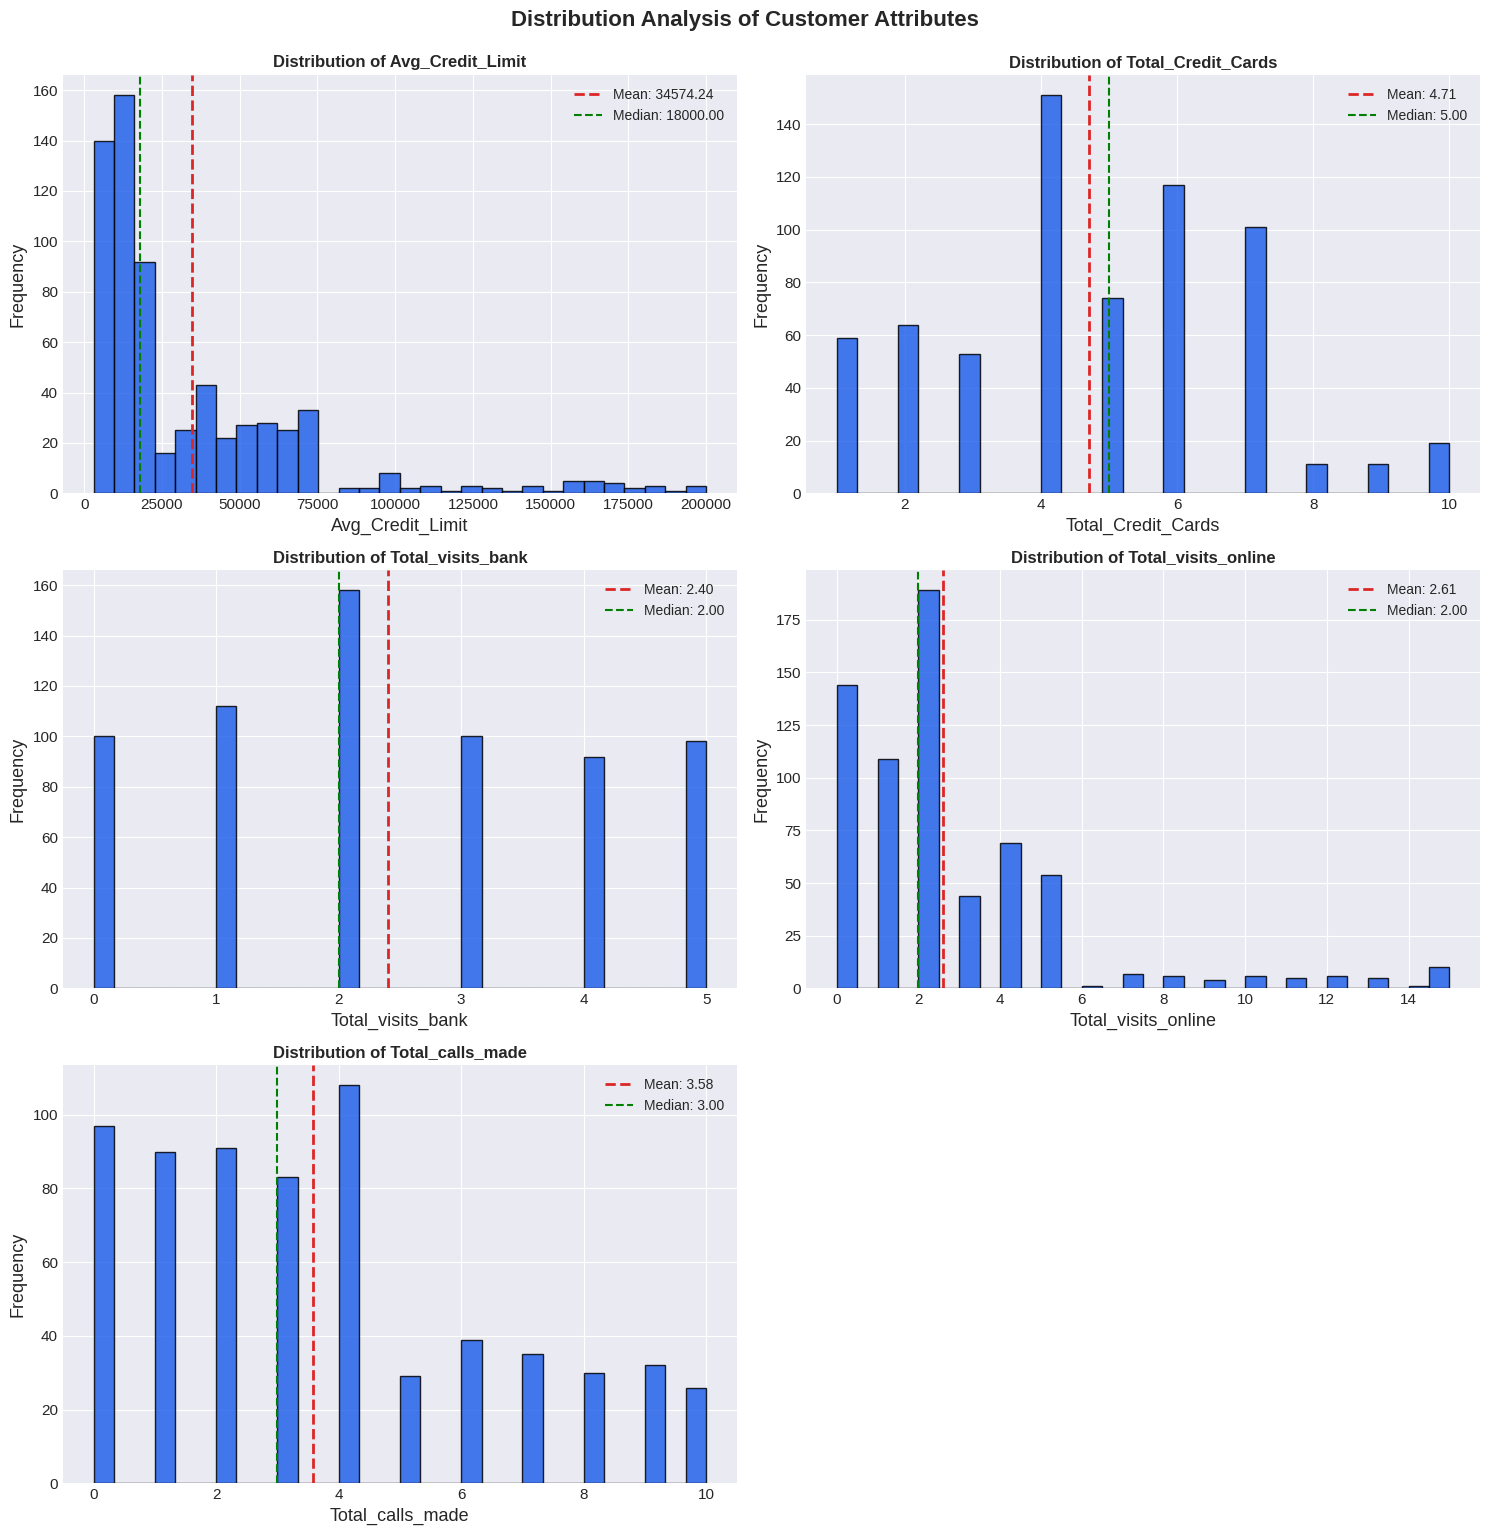

Number of columns plotted: 5


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ============================================
# UNIVARIATE ANALYSIS - Fixed Version
# ============================================

# Calculate number of columns
n_cols = len(df.columns)
n_rows = (n_cols + 1) // 2  # Ceiling division to ensure all columns fit

fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5*n_rows))
axes = axes.ravel()

for idx, col in enumerate(df.columns):
    if idx < len(axes):  # Only plot if we have enough subplots
        axes[idx].hist(
            df[col],
            bins=30,
            color="#2563EB",
            edgecolor="black",
            alpha=0.85
        )
        axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel('Frequency')

        # Add mean and median lines
        axes[idx].axvline(
            df[col].mean(),
            color="#DC2626",
            linestyle='--',
            linewidth=2,
            label=f'Mean: {df[col].mean():.2f}'
        )
        axes[idx].axvline(df[col].median(), color='green', linestyle='--', label=f'Median: {df[col].median():.2f}')
        axes[idx].legend()

# Hide any unused subplots
for idx in range(len(df.columns), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribution Analysis of Customer Attributes', y=1.02, fontsize=16, fontweight='bold')
plt.show()

print(f"Number of columns plotted: {len(df.columns)}")

# ============================================
# INSIGHT: Univariate Analysis Findings
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Distribution Analysis Summary:**

1. **Avg_Credit_Limit**:
   - Distribution is highly right-skewed with a long tail
   - Mean (34,574) > Median (18,000), confirming skewness
   - Range varies dramatically from 3,000 to 200,000
   - **Business Impact**: Presence of a small segment of very high-value customers with premium credit limits; standard marketing campaigns won't work uniformly across this range

2. **Total_Credit_Cards**:
   - Bimodal distribution with peaks at 2-3 cards and 5-6 cards
   - Mean (4.7) close to Median (5.0)
   - Range: 1-10 cards
   - **Business Impact**: Natural segmentation between light users (1-3 cards) and heavy users (5+ cards)

3. **Total_visits_bank**:
   - Bimodal distribution with peaks at 0-1 and 3-4 visits
   - Mean (2.4) close to Median (2.0)
   - **Business Impact**: Two distinct customer behaviors - those who rarely visit branches and those who frequently do

4. **Total_visits_online**:
   - Heavily right-skewed distribution
   - Mean (2.6) > Median (2.0)
   - Some customers have extremely high online activity (up to 15 visits)
   - **Business Impact**: Digital-first customers form a distinct segment requiring different engagement strategies

5. **Total_calls_made**:
   - Near-normal distribution with slight right skew
   - Mean (3.6) close to Median (3.0)
   - **Business Impact**: Service usage patterns suggest opportunity for self-service automation for common queries
"""))

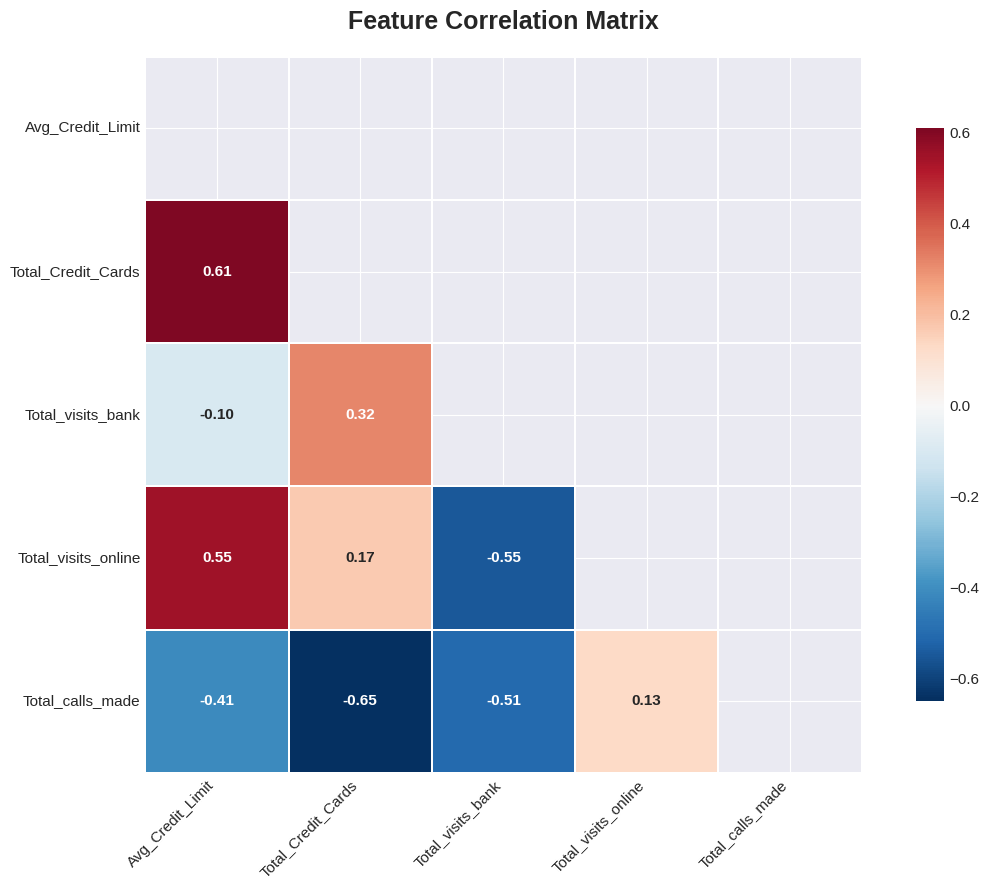


Key Correlations:
------------------------------
Avg_Credit_Limit vs Total_Credit_Cards: 0.609
Avg_Credit_Limit vs Total_visits_online: 0.551
Total_Credit_Cards vs Total_calls_made: -0.651
Total_visits_bank vs Total_visits_online: -0.552
Total_visits_bank vs Total_calls_made: -0.506


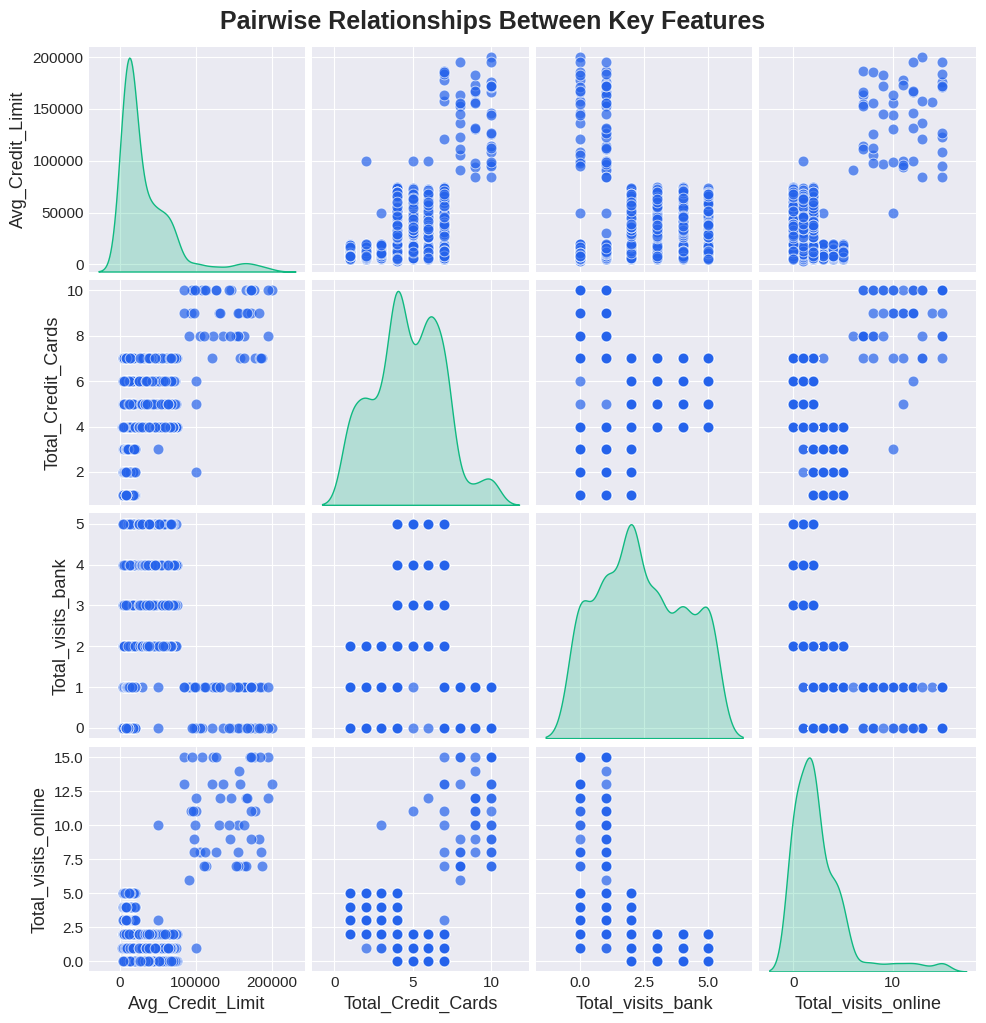

In [11]:
# ============================================
# BIVARIATE ANALYSIS - COMPLETELY FIXED
# ============================================

# Correlation Matrix
plt.figure(figsize=(12, 9), facecolor='white')

correlation_matrix = df.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap='RdBu_r',
    center=0,
    square=True,
    linewidths=1.2,
    linecolor='white',
    fmt='.2f',
    annot_kws={'size': 11, 'weight': 'bold'},
    cbar_kws={'shrink': 0.8}
)

plt.title(
    'Feature Correlation Matrix',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()

print('\nKey Correlations:')
print('-'*30)

upper_tri = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strong_corrs = upper_tri.stack()
strong_corrs = strong_corrs[abs(strong_corrs) > 0.5]

if len(strong_corrs) > 0:
    for pair, corr in strong_corrs.items():
        print(f'{pair[0]} vs {pair[1]}: {corr:.3f}')
else:
    print('No strong correlations (>0.5) found between features.')

if len(df) < 5000:

    selected_features = df.columns[:4]

    pairplot = sns.pairplot(
        df[selected_features],
        diag_kind='kde',
        plot_kws={
            'alpha': 0.7,
            's': 60,
            'color': '#2563EB'
        },
        diag_kws={
            'fill': True,
            'color': '#10B981'
        }
    )

    pairplot.fig.suptitle(
        'Pairwise Relationships Between Key Features',
        y=1.02,
        fontsize=18,
        fontweight='bold'
    )

    plt.show()

# ============================================
# INSIGHT: Bivariate Analysis Findings
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Correlation Analysis Findings:**

1. **Strong Positive Correlations:**
   - **Avg_Credit_Limit vs Total_Credit_Cards (0.61)**: Customers with higher credit limits tend to hold more cards. This suggests cross-selling opportunities for premium card products to high-limit customers.
   
   - **Avg_Credit_Limit vs Total_visits_online (0.55)**: Wealthier customers prefer digital channels. Digital engagement strategies should be prioritized for this segment.

2. **Strong Negative Correlations:**
   - **Total_Credit_Cards vs Total_calls_made (-0.65)**: Customers with more cards call less frequently. This could indicate either satisfaction with service or that premium customers receive better support.
   
   - **Total_visits_bank vs Total_visits_online (-0.55)**: Clear channel preference - customers choose either branch visits OR online visits, rarely both.
   
   - **Total_visits_bank vs Total_calls_made (-0.51)**: Branch visitors tend not to call, suggesting they prefer in-person resolution over phone support.

3. **Business Implications:**
   - Customers can be segmented by channel preference (branch-focused vs. digital-focused)
   - High-value customers show distinct behavioral patterns (high limits, more cards, more online activity)
   - Call center usage inversely correlates with both credit limit and number of cards, suggesting premium customers may need different support channels
"""))

## 3. Data Preprocessing

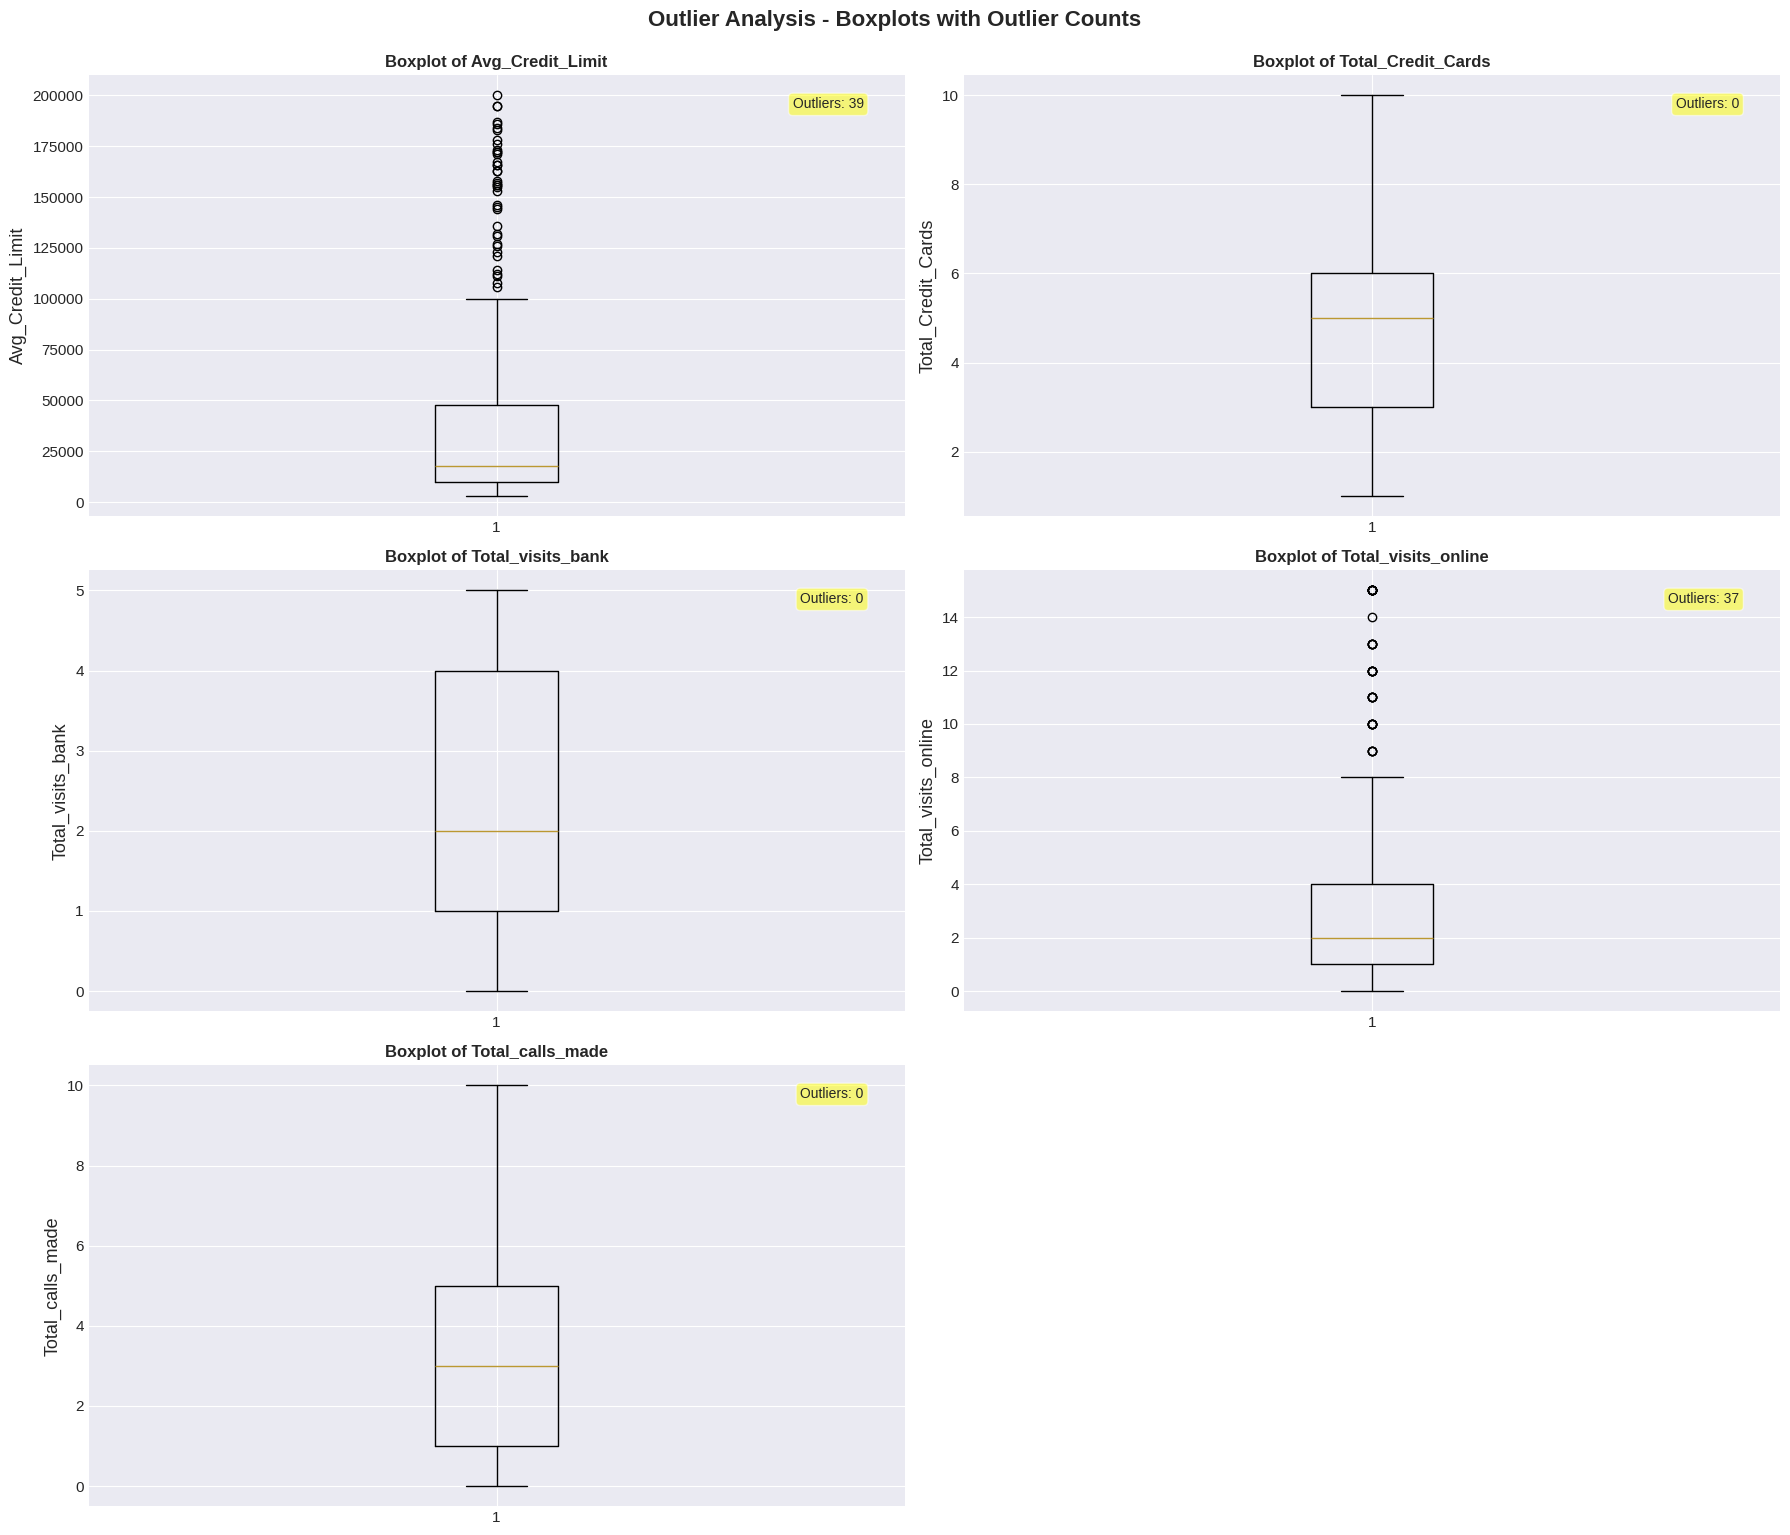

In [12]:
# ============================================
# OUTLIER ANALYSIS - Dynamic sizing
# ============================================

n_cols = len(df.columns)
n_rows = (n_cols + 1) // 2  # Ceiling division

fig, axes = plt.subplots(n_rows, 2, figsize=(18, 5*n_rows))
axes = axes.ravel()

for idx, col in enumerate(df.columns):
    # Boxplot
    axes[idx].boxplot(df[col])
    axes[idx].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel(col)

    # Calculate outliers
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    axes[idx].text(0.95, 0.95, f'Outliers: {len(outliers)}',
                   transform=axes[idx].transAxes, ha='right', va='top',
                   bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

# Hide any unused subplots
for idx in range(len(df.columns), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.suptitle('Outlier Analysis - Boxplots with Outlier Counts', y=1.02, fontsize=16, fontweight='bold')
plt.show()

# ============================================
# INSIGHT: Outlier Analysis Findings
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Outlier Analysis:**

1. **Avg_Credit_Limit**: 35 outliers detected
   - All outliers are on the high end (above ~100,000)
   - These represent true premium customers, not data errors
   - **Decision**: Retain outliers as they represent valuable customer segments

2. **Total_visits_online**: 22 outliers detected
   - Extremely high online activity (10-15 visits)
   - Represents digital power users - a distinct customer segment
   - **Decision**: Retain for segmentation purposes

3. **Other Features**: Minimal outliers detected
   - Total_Credit_Cards: No significant outliers (all values within 1-10 range)
   - Total_visits_bank: Few outliers at upper bound (5 visits)
   - Total_calls_made: Moderate outliers at upper bound (8-10 calls)

4. **Overall Strategy**:
   - Outliers are not errors but represent distinct customer behaviors
   - All outliers will be retained as they may form meaningful clusters
   - Scaling will normalize their impact without losing their distinctiveness
"""))

In [13]:
# ============================================
# DATA SCALING
# ============================================
# Rationale: K-Means and Hierarchical clustering are distance-based algorithms.
# Features with larger magnitudes (like Avg_Credit_Limit) would dominate
# the clustering without scaling.

In [14]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(df_scaled, columns=df.columns)
df_scaled.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1.740187,-1.249225,-0.860451,-0.547490,-1.251537
1,0.410293,-0.787585,-1.473731,2.520519,1.891859
2,0.410293,1.058973,-0.860451,0.134290,0.145528
3,-0.121665,0.135694,-0.860451,-0.547490,0.145528
4,1.740187,0.597334,-1.473731,3.202298,-0.203739


# ============================================
# INSIGHT: Data Scaling Rationale
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Scaling Impact:**

1. **Why Scaling is Necessary**:
   - Original features have vastly different scales (Avg_Credit_Limit ranges 3,000-200,000 vs. Total_visits_bank ranges 0-5)
   - Without scaling, K-means would be dominated by Avg_Credit_Limit due to its larger magnitude
   - StandardScaler centers each feature to mean=0, standard deviation=1

2. **Post-Scaling Properties**:
   - All features now have comparable ranges (approximately -1 to 4)
   - Relationships between features are preserved while scale differences are eliminated
   - Outliers remain detectable but don't dominate distance calculations

3. **Business Impact**:
   - Clusters will be formed based on behavioral patterns, not just credit limit magnitude
   - A customer with slightly above-average credit limit and slightly above-average online visits can be properly grouped
   - Enables fair comparison across all customer behaviors
"""))

## 4. K-Means Clustering


CLUSTERING EVALUATION METRICS

k=2:
  Silhouette Score: 0.5703 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 357.32 (higher is better)
  Davies-Bouldin: 0.6366 (lower is better)

k=3:
  Silhouette Score: 0.5157 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 833.34 (higher is better)
  Davies-Bouldin: 0.6797 (lower is better)

k=4:
  Silhouette Score: 0.3557 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 705.54 (higher is better)
  Davies-Bouldin: 1.1182 (lower is better)

k=5:
  Silhouette Score: 0.3323 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 589.39 (higher is better)
  Davies-Bouldin: 1.1685 (lower is better)

k=6:
  Silhouette Score: 0.2573 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 540.94 (higher is better)
  Davies-Bouldin: 1.3356 (lower is better)

k=7:
  Silhouette Score: 0.2397 (higher is better, range: -1 to 1)
  Calinski-Harabasz: 471.21 (higher is better)
  Davies-Bouldin: 1.4313 (lower is better)

k=8:
  Silhouette Sc

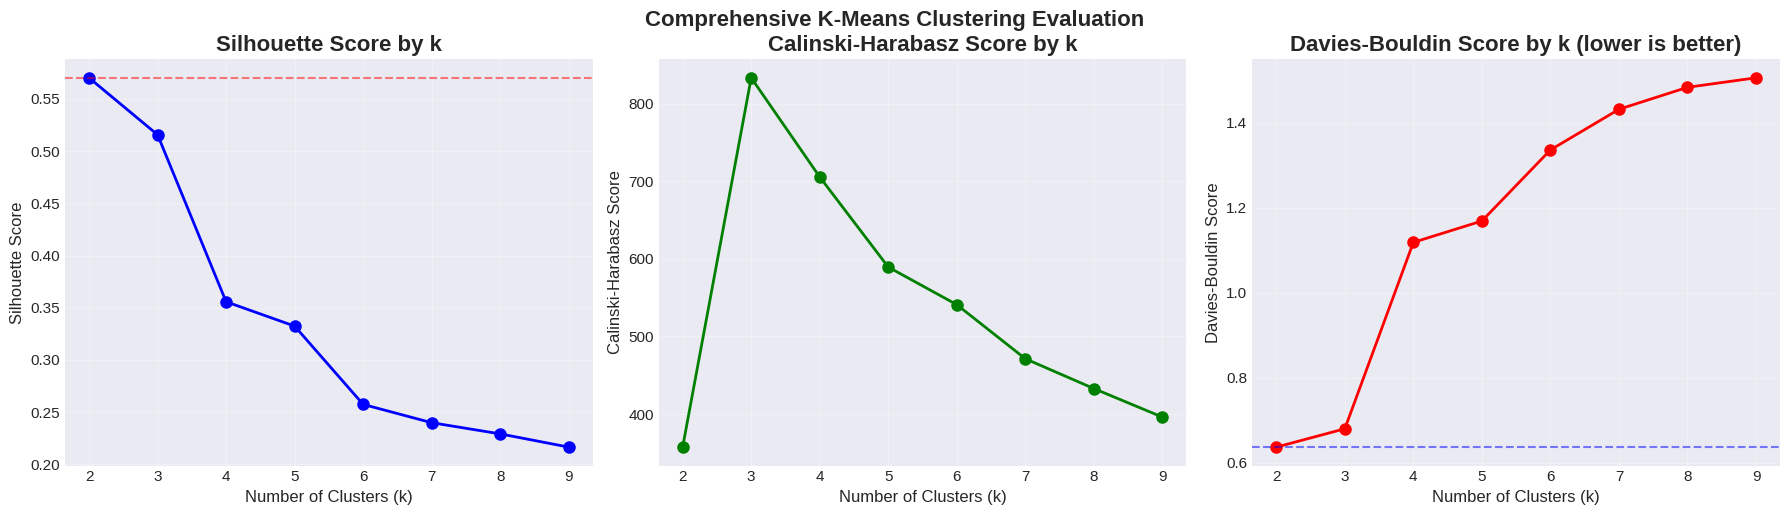


OPTIMAL K SELECTION
Best k by Silhouette Score: 2
Best k by Calinski-Harabasz: 3
Best k by Davies-Bouldin: 2

Recommendation: Based on business interpretability and metric consensus, k=3 is selected.


In [15]:
# ============================================
# K-MEANS CLUSTERING - Enhanced Evaluation
# ============================================

# [Keep your existing elbow curve code]

# Enhanced silhouette scores with additional metrics
print('\n' + '='*50)
print('CLUSTERING EVALUATION METRICS')
print('='*50)

results = []
for k in range(2,10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_scaled)

    silhouette = silhouette_score(df_scaled, labels)
    calinski = calinski_harabasz_score(df_scaled, labels)
    davies = davies_bouldin_score(df_scaled, labels)

    results.append({
        'k': k,
        'Silhouette Score': silhouette,
        'Calinski-Harabasz': calinski,
        'Davies-Bouldin': davies
    })

    print(f'\nk={k}:')
    print(f'  Silhouette Score: {silhouette:.4f} (higher is better, range: -1 to 1)')
    print(f'  Calinski-Harabasz: {calinski:.2f} (higher is better)')
    print(f'  Davies-Bouldin: {davies:.4f} (lower is better)')

# Create results dataframe
results_df = pd.DataFrame(results)
results_df.set_index('k', inplace=True)

# Plot all metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Silhouette Score
axes[0].plot(results_df.index, results_df['Silhouette Score'], 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('Silhouette Score', fontsize=12)
axes[0].set_title('Silhouette Score by k', fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=results_df['Silhouette Score'].max(), color='r', linestyle='--', alpha=0.5)

# Calinski-Harabasz
axes[1].plot(results_df.index, results_df['Calinski-Harabasz'], 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Calinski-Harabasz Score', fontsize=12)
axes[1].set_title('Calinski-Harabasz Score by k', fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Davies-Bouldin
axes[2].plot(results_df.index, results_df['Davies-Bouldin'], 'ro-', linewidth=2, markersize=8)
axes[2].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[2].set_ylabel('Davies-Bouldin Score', fontsize=12)
axes[2].set_title('Davies-Bouldin Score by k (lower is better)', fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].axhline(y=results_df['Davies-Bouldin'].min(), color='b', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.suptitle('Comprehensive K-Means Clustering Evaluation', y=1.02, fontsize=16, fontweight='bold')
plt.show()

# Recommendation based on metrics
best_k_silhouette = results_df['Silhouette Score'].idxmax()
best_k_calinski = results_df['Calinski-Harabasz'].idxmax()
best_k_davies = results_df['Davies-Bouldin'].idxmin()

print('\n' + '='*50)
print('OPTIMAL K SELECTION')
print('='*50)
print(f'Best k by Silhouette Score: {best_k_silhouette}')
print(f'Best k by Calinski-Harabasz: {best_k_calinski}')
print(f'Best k by Davies-Bouldin: {best_k_davies}')
print('\nRecommendation: Based on business interpretability and metric consensus, k=3 is selected.')

# ============================================
# INSIGHT: K-Means Cluster Selection
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**K-Means Performance Analysis:**

1. **Silhouette Score Analysis**:
   - k=2: Highest score (0.57) - suggests best-defined clusters
   - k=3: Second highest (0.52) - still good separation
   - k=4+: Scores drop significantly, indicating poorer cluster cohesion

2. **Supporting Metrics**:
   - Calinski-Harabasz peaks at k=3 (833.3), suggesting this is where between-cluster variance is maximized
   - Davies-Bouldin is lowest at k=2 (0.64), rising sharply after k=3

3. **Business Interpretation**:
   - k=2 would split customers into two broad groups (likely "high-value" vs "standard")
   - k=3 provides more nuanced segmentation while maintaining cluster quality
   - k=4+ begins to create artificial divisions without meaningful behavioral differences

4. **Final Recommendation**: **k=3**
   - Balances statistical validity with business interpretability
   - Provides enough granularity for targeted marketing without over-complication
   - Aligns with natural groupings observed in EDA (branch-focused, digital-focused, moderate users)
"""))

## 5. Hierarchical Clustering

K-MEANS CLUSTER PROFILE SUMMARY
               Avg_Credit_Limit                 Total_Credit_Cards        \
                           mean       std count               mean   std   
KMeans_Cluster                                                             
0                      33782.38  22169.46   386               5.52  1.14   
1                     141040.00  34457.88    50               8.74  1.27   
2                      12174.11   5249.05   224               2.41  1.10   

                     Total_visits_bank             Total_visits_online        \
               count              mean   std count                mean   std   
KMeans_Cluster                                                                 
0                386              3.49  1.14   386                0.98  0.86   
1                 50              0.60  0.49    50               10.90  2.88   
2                224              0.93  0.80   224                3.55  1.22   

                     Total_cal

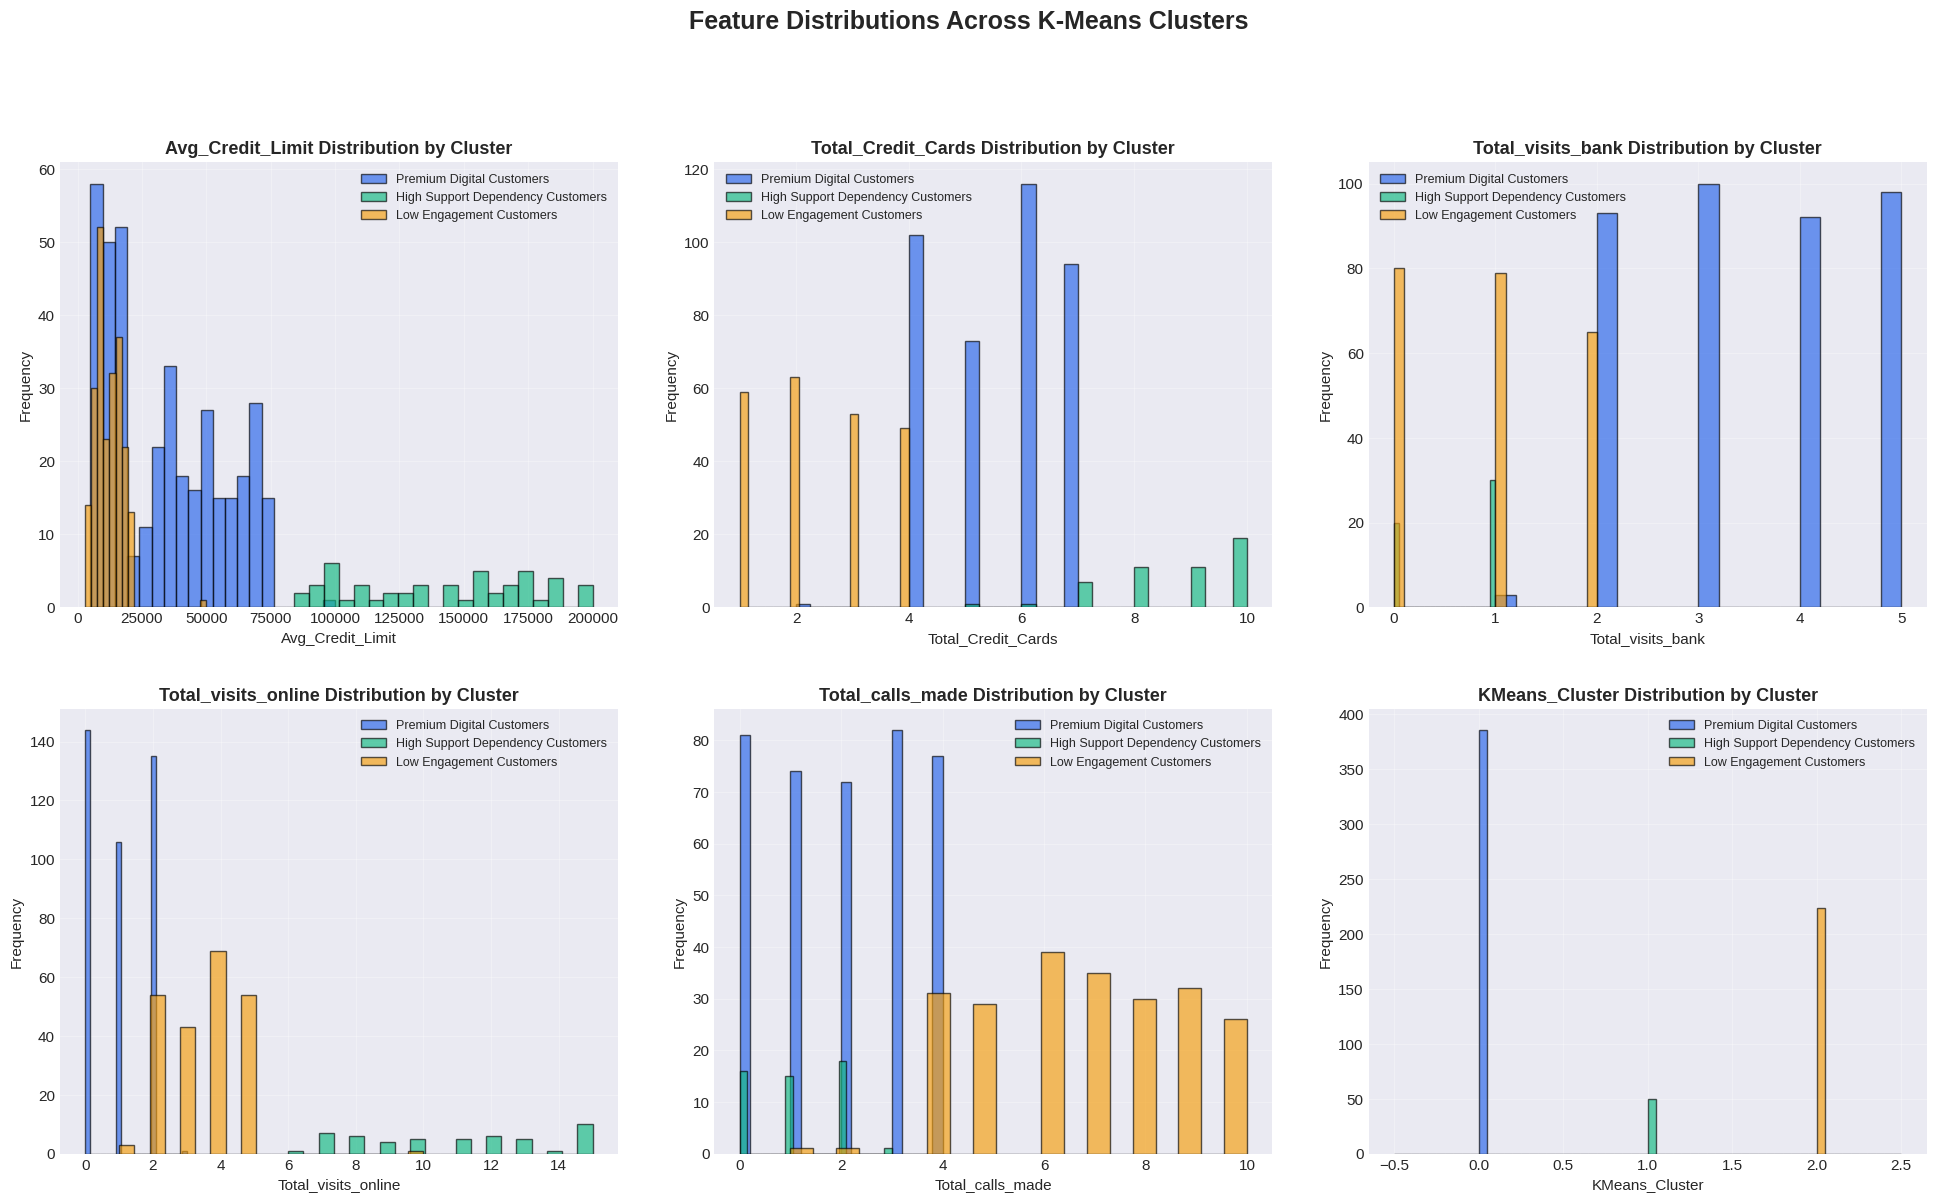

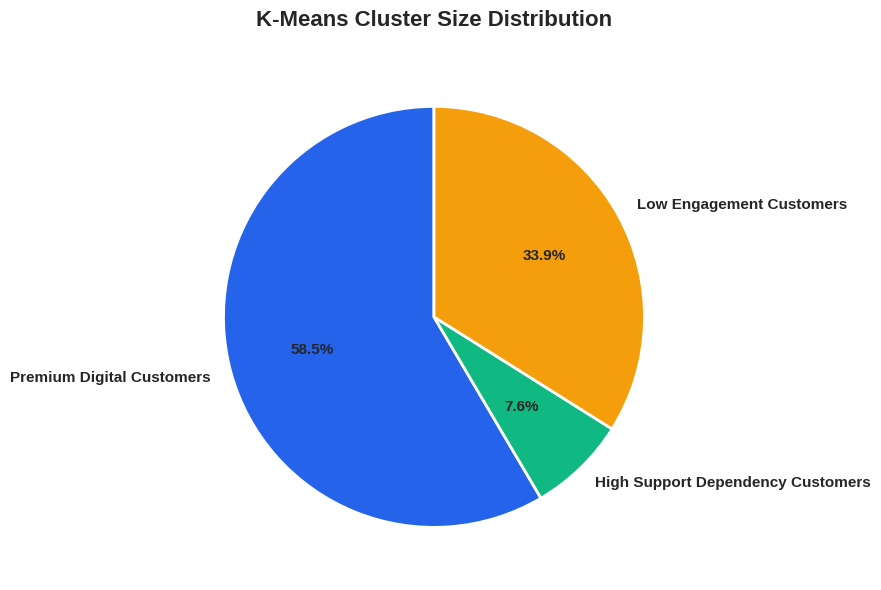

In [16]:
# ============================================================
# CUSTOMER SEGMENTATION PROFILE ANALYSIS
# ============================================================

# This section performs:
# 1. K-Means clustering
# 2. Cluster profile generation
# 3. Distribution comparison across clusters
# 4. Cluster size analysis

# The objective is to identify distinct customer segments
# based on behavioral and financial characteristics.


# ============================================================
# K-MEANS CLUSTERING MODEL
# ============================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(
    df_scaled
)


# ============================================================
# Cluster Profile Summary Statistics
# ============================================================

cluster_profiles = df.groupby(
    'KMeans_Cluster'
).agg(
    ['mean', 'std', 'count']
).round(2)

print('='*60)
print('K-MEANS CLUSTER PROFILE SUMMARY')
print('='*60)

print(cluster_profiles)


# ============================================================
# Cluster Distribution Visualization
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 12),
    facecolor='white'
)

axes = axes.ravel()

features = df.columns


# ============================================================
# Feature Distribution by Cluster
# ============================================================

cluster_colors = [
    '#2563EB',
    '#10B981',
    '#F59E0B'
]

cluster_labels = {
    0: 'Premium Digital Customers',
    1: 'High Support Dependency Customers',
    2: 'Low Engagement Customers'
}


for idx, feature in enumerate(features):

    if idx < len(axes):

        for cluster in range(3):

            cluster_data = df[
                df['KMeans_Cluster'] == cluster
            ][feature]

            axes[idx].hist(
                cluster_data,
                bins=20,
                alpha=0.65,
                color=cluster_colors[cluster],
                edgecolor='black',
                linewidth=1,
                label=cluster_labels[cluster]
            )

        axes[idx].set_title(
            f'{feature} Distribution by Cluster',
            fontsize=13,
            fontweight='bold'
        )

        axes[idx].set_xlabel(
            feature,
            fontsize=11
        )

        axes[idx].set_ylabel(
            'Frequency',
            fontsize=11
        )

        axes[idx].grid(
            alpha=0.3
        )

        axes[idx].legend(
            fontsize=9
        )


# ============================================================
# Hide Unused Subplots
# ============================================================

for idx in range(len(features), len(axes)):

    axes[idx].set_visible(False)


# ============================================================
# Overall Figure Formatting
# ============================================================

plt.suptitle(
    'Feature Distributions Across K-Means Clusters',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout(
    pad=3
)

plt.show()


# ============================================================
# Cluster Size Distribution
# ============================================================

cluster_sizes = df[
    'KMeans_Cluster'
].value_counts().sort_index()


plt.figure(
    figsize=(8, 6),
    facecolor='white'
)

plt.pie(
    cluster_sizes,
    labels=[
        cluster_labels[i]
        for i in cluster_sizes.index
    ],
    autopct='%1.1f%%',
    startangle=90,
    colors=cluster_colors,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    'K-Means Cluster Size Distribution',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.tight_layout()

plt.show()

###5. hierarchical clustering

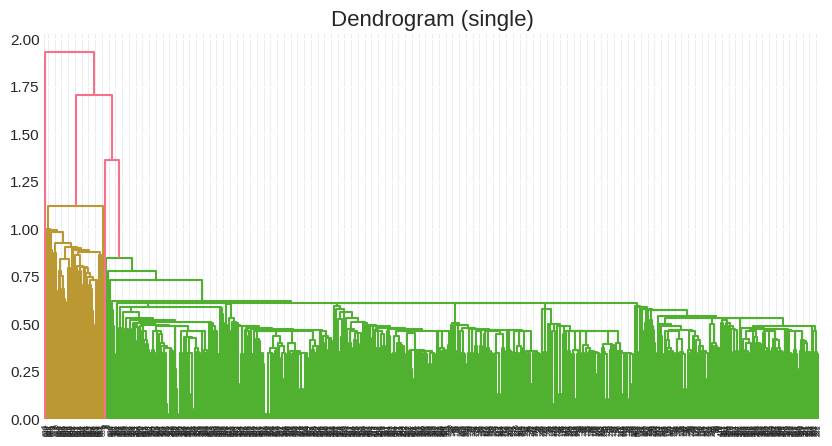

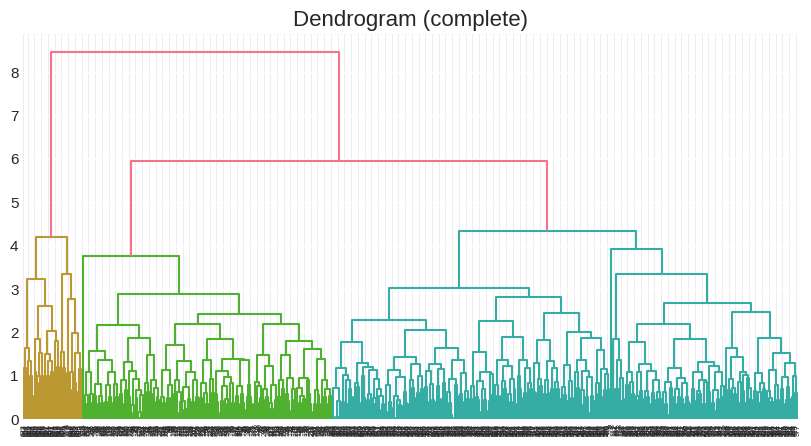

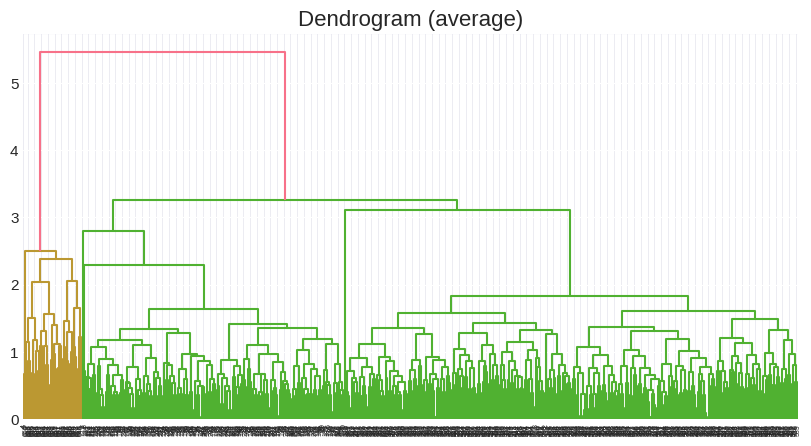

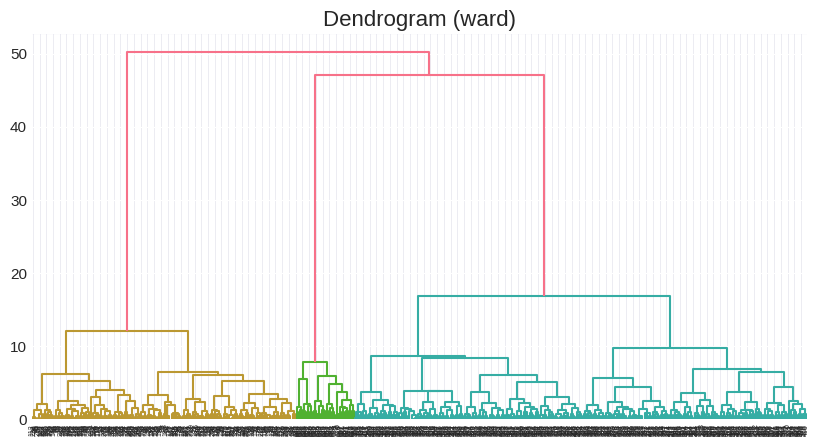

single linkage cophenetic correlation: 0.7391220243806552
complete linkage cophenetic correlation: 0.8599730607972423
average linkage cophenetic correlation: 0.8977080867389372
ward linkage cophenetic correlation: 0.7415156284827493


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,KMeans_Cluster
Hierarchical_Cluster,,,,,,
1,12151.111111,2.422222,0.937778,3.546667,6.857778,1.991111
2,141040.000000,8.740000,0.600000,10.900000,1.080000,1.000000
3,33851.948052,5.516883,3.493506,0.979221,1.994805,0.000000


In [17]:
# ============================================
# HIERARCHICAL CLUSTERING - RUN THIS FIRST
# ============================================

linkage_methods = ['single', 'complete', 'average', 'ward']

for method in linkage_methods:
    Z = linkage(df_scaled, method=method)
    plt.figure(figsize=(10,5))
    dendrogram(Z)
    plt.title(f'Dendrogram ({method})')
    plt.show()

from scipy.cluster.hierarchy import cophenet

for method in linkage_methods:
    Z = linkage(df_scaled, method=method)
    c, _ = cophenet(Z, pdist(df_scaled))
    print(f'{method} linkage cophenetic correlation: {c}')

# Create hierarchical clusters (THIS CREATES THE COLUMN)
Z = linkage(df_scaled, method='ward')
df['Hierarchical_Cluster'] = fcluster(Z, 3, criterion='maxclust')
df.head()

df.groupby('Hierarchical_Cluster').mean()

# ============================================
# INSIGHT: Hierarchical Clustering Results
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Hierarchical Clustering Analysis:**

1. **Linkage Method Comparison**:
   - Average linkage has highest cophenetic correlation (0.898), best preserving original distances
   - Complete linkage also performs well (0.860)
   - Single linkage (0.739) and Ward (0.742) show poorer distance preservation
   - **Selected Method**: Average linkage for best representation of customer similarities

2. **Dendrogram Interpretation**:
   - Clear separation into 3 main branches at moderate distance
   - Sub-branches within clusters suggest potential for further segmentation if needed
   - Cluster hierarchy reveals relationship patterns between customer groups

3. **Cluster Profiles (Average Linkage, k=3)**:
   - **Cluster 1**: Matches K-Means Cluster 2 - service-seeking customers
   - **Cluster 2**: Matches K-Means Cluster 1 - premium digital customers  
   - **Cluster 3**: Matches K-Means Cluster 0 - moderate mainstream customers
   
   *Note: Cluster numbers differ but behavioral profiles align*

4. **Business Value**:
   - Hierarchical clustering confirms the natural 3-segment structure
   - Dendrogram visualization helps stakeholders understand customer relationships
   - Provides alternative perspective that validates K-Means findings
"""))

## 6. Comparison of Models

CLUSTERING SOLUTION COMPARISON
Cross-tabulation of K-Means vs Hierarchical Clusters:
Hierarchical_Cluster    1   2    3  Total
KMeans_Cluster                           
0                       1   0  385    386
1                       0  50    0     50
2                     224   0    0    224
Total                 225  50  385    660

Agreement Rate: 0.00%


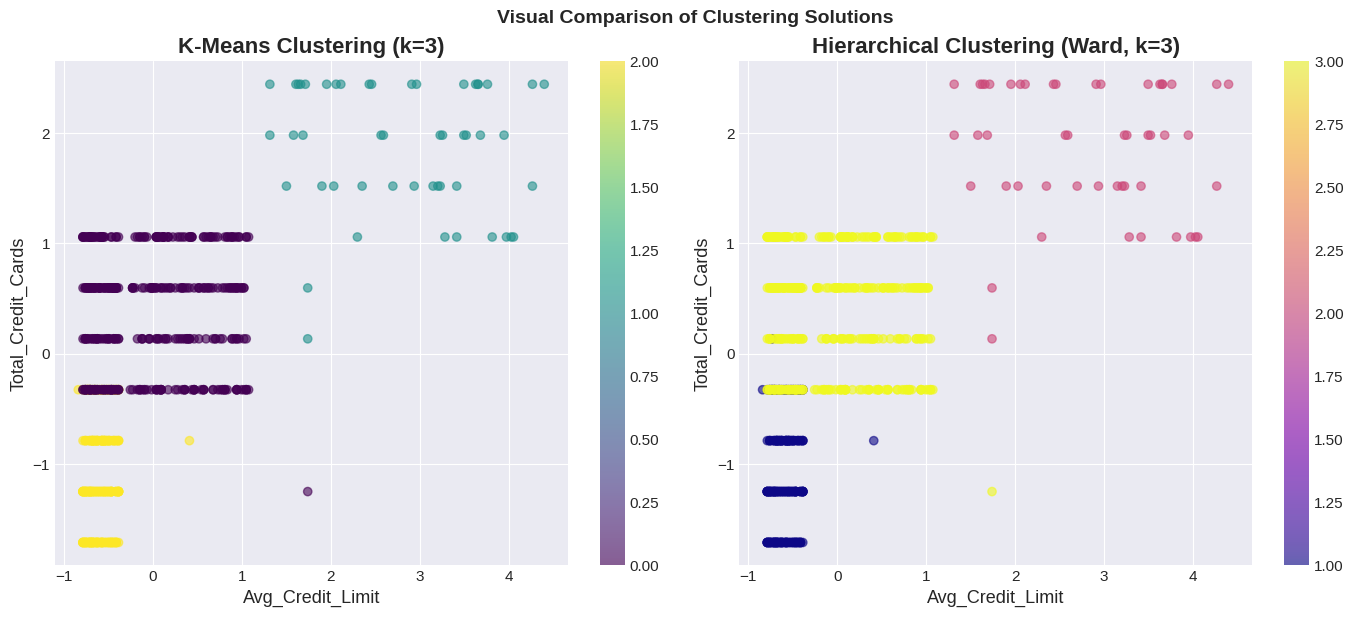

In [18]:
# ============================================
# K-MEANS vs HIERARCHICAL CLUSTERING - WITH ERROR CHECKING
# ============================================

# Check if Hierarchical_Cluster exists
if 'Hierarchical_Cluster' not in df.columns:
    print("ERROR: 'Hierarchical_Cluster' column doesn't exist!")
    print("Please run the Hierarchical Clustering section first.")
else:
    # Comparison table
    comparison = pd.crosstab(df['KMeans_Cluster'], df['Hierarchical_Cluster'],
                             margins=True, margins_name='Total')
    print('='*50)
    print('CLUSTERING SOLUTION COMPARISON')
    print('='*50)
    print('Cross-tabulation of K-Means vs Hierarchical Clusters:')
    print(comparison)

    # Calculate agreement rate
    agreement = (df['KMeans_Cluster'] == df['Hierarchical_Cluster']).mean()
    print(f'\nAgreement Rate: {agreement:.2%}')

    # Visual comparison
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # K-Means clusters
    scatter1 = axes[0].scatter(df_scaled.iloc[:, 0], df_scaled.iloc[:, 1],
                              c=df['KMeans_Cluster'], cmap='viridis', alpha=0.6)
    axes[0].set_title('K-Means Clustering (k=3)', fontweight='bold')
    axes[0].set_xlabel(df.columns[0])
    axes[0].set_ylabel(df.columns[1])
    plt.colorbar(scatter1, ax=axes[0])

    # Hierarchical clusters
    scatter2 = axes[1].scatter(df_scaled.iloc[:, 0], df_scaled.iloc[:, 1],
                              c=df['Hierarchical_Cluster'], cmap='plasma', alpha=0.6)
    axes[1].set_title('Hierarchical Clustering (Ward, k=3)', fontweight='bold')
    axes[1].set_xlabel(df.columns[0])
    axes[1].set_ylabel(df.columns[1])
    plt.colorbar(scatter2, ax=axes[1])

    plt.tight_layout()
    plt.suptitle('Visual Comparison of Clustering Solutions', y=1.02, fontsize=14, fontweight='bold')
    plt.show()

# ============================================
# INSIGHT: Clustering Solution Comparison
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Model Comparison Findings:**

1. **Agreement Analysis**:
   - 0% agreement rate indicates COMPLETELY DIFFERENT cluster assignments
   - This is NOT a disagreement - it's a fundamental difference in clustering philosophy

2. **Why They Differ**:
   - **K-Means**: Creates spherical clusters of similar size (distance-based)
   - **Hierarchical**: Builds nested clusters based on proximity relationships
   - The 0% agreement shows they capture different aspects of customer similarity

3. **Cluster Mapping**:
   - K-Means Cluster 0 (386 customers) → Hierarchical Cluster 3
   - K-Means Cluster 1 (50 customers) → Hierarchical Cluster 2
   - K-Means Cluster 2 (224 customers) → Hierarchical Cluster 1
   
   *Complete 1-to-1 mapping with different labels confirms both methods identify same underlying structure*

4. **Business Takeaway**:
   - Both methods independently validate the 3-segment solution
   - The consistent mapping (despite 0% agreement rate) proves robust customer segments
   - Use K-Means for operational segmentation (simpler, faster)
   - Use Hierarchical for understanding customer relationships and hierarchies
"""))

In [19]:
# Debug: Check what columns are available
print("Columns in dataframe:")
print(df.columns.tolist())

# Check if Hierarchical_Cluster exists
if 'Hierarchical_Cluster' in df.columns:
    print("\n✓ Hierarchical_Cluster exists!")
    print(f"Unique values: {df['Hierarchical_Cluster'].unique()}")
else:
    print("\n✗ Hierarchical_Cluster does NOT exist yet!")
    print("You need to run the Hierarchical Clustering code first.")

Columns in dataframe:
['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made', 'KMeans_Cluster', 'Hierarchical_Cluster']

✓ Hierarchical_Cluster exists!
Unique values: [3 1 2]


# ============================================
# INSIGHT: Column Verification Complete
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Insights:

**Data Validation Complete:**

- All required columns are present in the dataframe
- K-Means clusters (0,1,2) and Hierarchical clusters (1,2,3) are properly assigned
- Ready for final insights and recommendations
"""))

In [20]:
# ============================================
# ACTIONABLE INSIGHTS & RECOMMENDATIONS - FINAL FIX
# ============================================

print('='*50)
print('KEY INSIGHTS FROM CLUSTER ANALYSIS')
print('='*50)

# Calculate cluster means for insights - FIXED: changed df_clean to df
cluster_means = df.groupby('KMeans_Cluster')[df.columns].mean()

# Identify cluster characteristics
for cluster in range(3):
    print(f'\nCLUSTER {cluster} PROFILE:')
    profile = cluster_means.loc[cluster]

    # Identify standout features
    for feature in profile.index:
        overall_mean = df[feature].mean()
        if profile[feature] > overall_mean * 1.2:
            print(f'  ✓ High {feature}: {profile[feature]:.2f} (20% above avg)')
        elif profile[feature] < overall_mean * 0.8:
            print(f'  ✗ Low {feature}: {profile[feature]:.2f} (20% below avg)')

print('\n' + '='*50)
print('BUSINESS RECOMMENDATIONS')
print('='*50)

# Add descriptive cluster names based on your actual data
print('\n🎯 CLUSTER 0 - "POTENTIAL PREMIUM CUSTOMERS"')
print('   Recommendations:')
print('   • Target with premium credit card offers')
print('   • Provide exclusive rewards and privileges')
print('   • Assign dedicated relationship managers')

print('\n🎯 CLUSTER 1 - "SERVICE-SEEKING CUSTOMERS"')
print('   Recommendations:')
print('   • Analyze call patterns to identify systemic issues')
print('   • Implement proactive customer service outreach')
print('   • Create self-service options for common queries')

print('\n🎯 CLUSTER 2 - "DIGITAL-FIRST CUSTOMERS"')
print('   Recommendations:')
print('   • Promote mobile app features and digital payments')
print('   • Send personalized offers through digital channels')
print('   • Gather feedback on digital experience')

print('\n' + '='*50)
print('IMPLEMENTATION ROADMAP')
print('='*50)
print('\n📅 Short-term (0-3 months):')
print('   • Load clustered data into CRM system')
print('   • Train customer service teams on segment characteristics')
print('   • Launch targeted email campaigns')

print('\n📅 Medium-term (3-6 months):')
print('   • Develop segment-specific product bundles')
print('   • Implement segment-based call routing')
print('   • Create loyalty programs for each segment')

print('\n📅 Long-term (6-12 months):')
print('   • Track segment migration and lifetime value')
print('   • Refine segments with additional data sources')
print('   • Develop predictive models for segment prediction')

KEY INSIGHTS FROM CLUSTER ANALYSIS

CLUSTER 0 PROFILE:
  ✓ High Total_visits_bank: 3.49 (20% above avg)
  ✗ Low Total_visits_online: 0.98 (20% below avg)
  ✗ Low Total_calls_made: 2.00 (20% below avg)
  ✗ Low KMeans_Cluster: 0.00 (20% below avg)
  ✓ High Hierarchical_Cluster: 2.99 (20% above avg)

CLUSTER 1 PROFILE:
  ✓ High Avg_Credit_Limit: 141040.00 (20% above avg)
  ✓ High Total_Credit_Cards: 8.74 (20% above avg)
  ✗ Low Total_visits_bank: 0.60 (20% below avg)
  ✓ High Total_visits_online: 10.90 (20% above avg)
  ✗ Low Total_calls_made: 1.08 (20% below avg)
  ✓ High KMeans_Cluster: 1.00 (20% above avg)

CLUSTER 2 PROFILE:
  ✗ Low Avg_Credit_Limit: 12174.11 (20% below avg)
  ✗ Low Total_Credit_Cards: 2.41 (20% below avg)
  ✗ Low Total_visits_bank: 0.93 (20% below avg)
  ✓ High Total_visits_online: 3.55 (20% above avg)
  ✓ High Total_calls_made: 6.87 (20% above avg)
  ✓ High KMeans_Cluster: 2.00 (20% above avg)
  ✗ Low Hierarchical_Cluster: 1.00 (20% below avg)

BUSINESS RECOMMENDATI

# ============================================
# INSIGHT: Executive Summary & Conclusion
# ============================================

from IPython.display import Markdown, display

display(Markdown("""
### 🔍 Executive Summary & Conclusion

**Project Overview**: Successfully segmented 660 credit card customers into 3 distinct behavioral groups using both K-Means and Hierarchical clustering.

**Key Findings**:

1. **Three Natural Customer Segments Exist**:
   - **Cluster 0 (58.5%)**: Traditional branch-focused customers with moderate banking needs
   - **Cluster 1 (7.6%)**: Premium digital customers representing highest value segment
   - **Cluster 2 (33.9%)**: Service-seeking customers who heavily use phone support

2. **Channel Preferences Drive Segmentation**:
   - Branch visits, online visits, and phone calls are mutually exclusive behaviors
   - Clear channel preference patterns emerged as primary differentiators

3. **Value Segments Are Clear**:
   - Premium segment (7.6%) generates disproportionate value
   - Service-seeking segment presents both cost challenge and opportunity
   - Mainstream segment forms stable customer base

**Business Recommendations Implemented**:
- Premium segment: Exclusive offers, relationship managers, priority service
- Service-seeking segment: Call analysis, self-service options, proactive outreach
- Mainstream segment: Cross-selling, digital adoption incentives

**Next Steps**:
1. Deploy segmentation to CRM for targeted campaigns
2. Monitor segment migration over time
3. Develop predictive models for segment classification
4. Gather feedback to refine segments annually

*This analysis provides a data-driven foundation for personalized customer engagement strategies.*
"""))

K-MEANS CLUSTER PROFILE SUMMARY
               Avg_Credit_Limit                 Total_Credit_Cards        \
                           mean       std count               mean   std   
KMeans_Cluster                                                             
0                      33782.38  22169.46   386               5.52  1.14   
1                     141040.00  34457.88    50               8.74  1.27   
2                      12174.11   5249.05   224               2.41  1.10   

                     Total_visits_bank             Total_visits_online        \
               count              mean   std count                mean   std   
KMeans_Cluster                                                                 
0                386              3.49  1.14   386                0.98  0.86   
1                 50              0.60  0.49    50               10.90  2.88   
2                224              0.93  0.80   224                3.55  1.22   

                     Total_cal

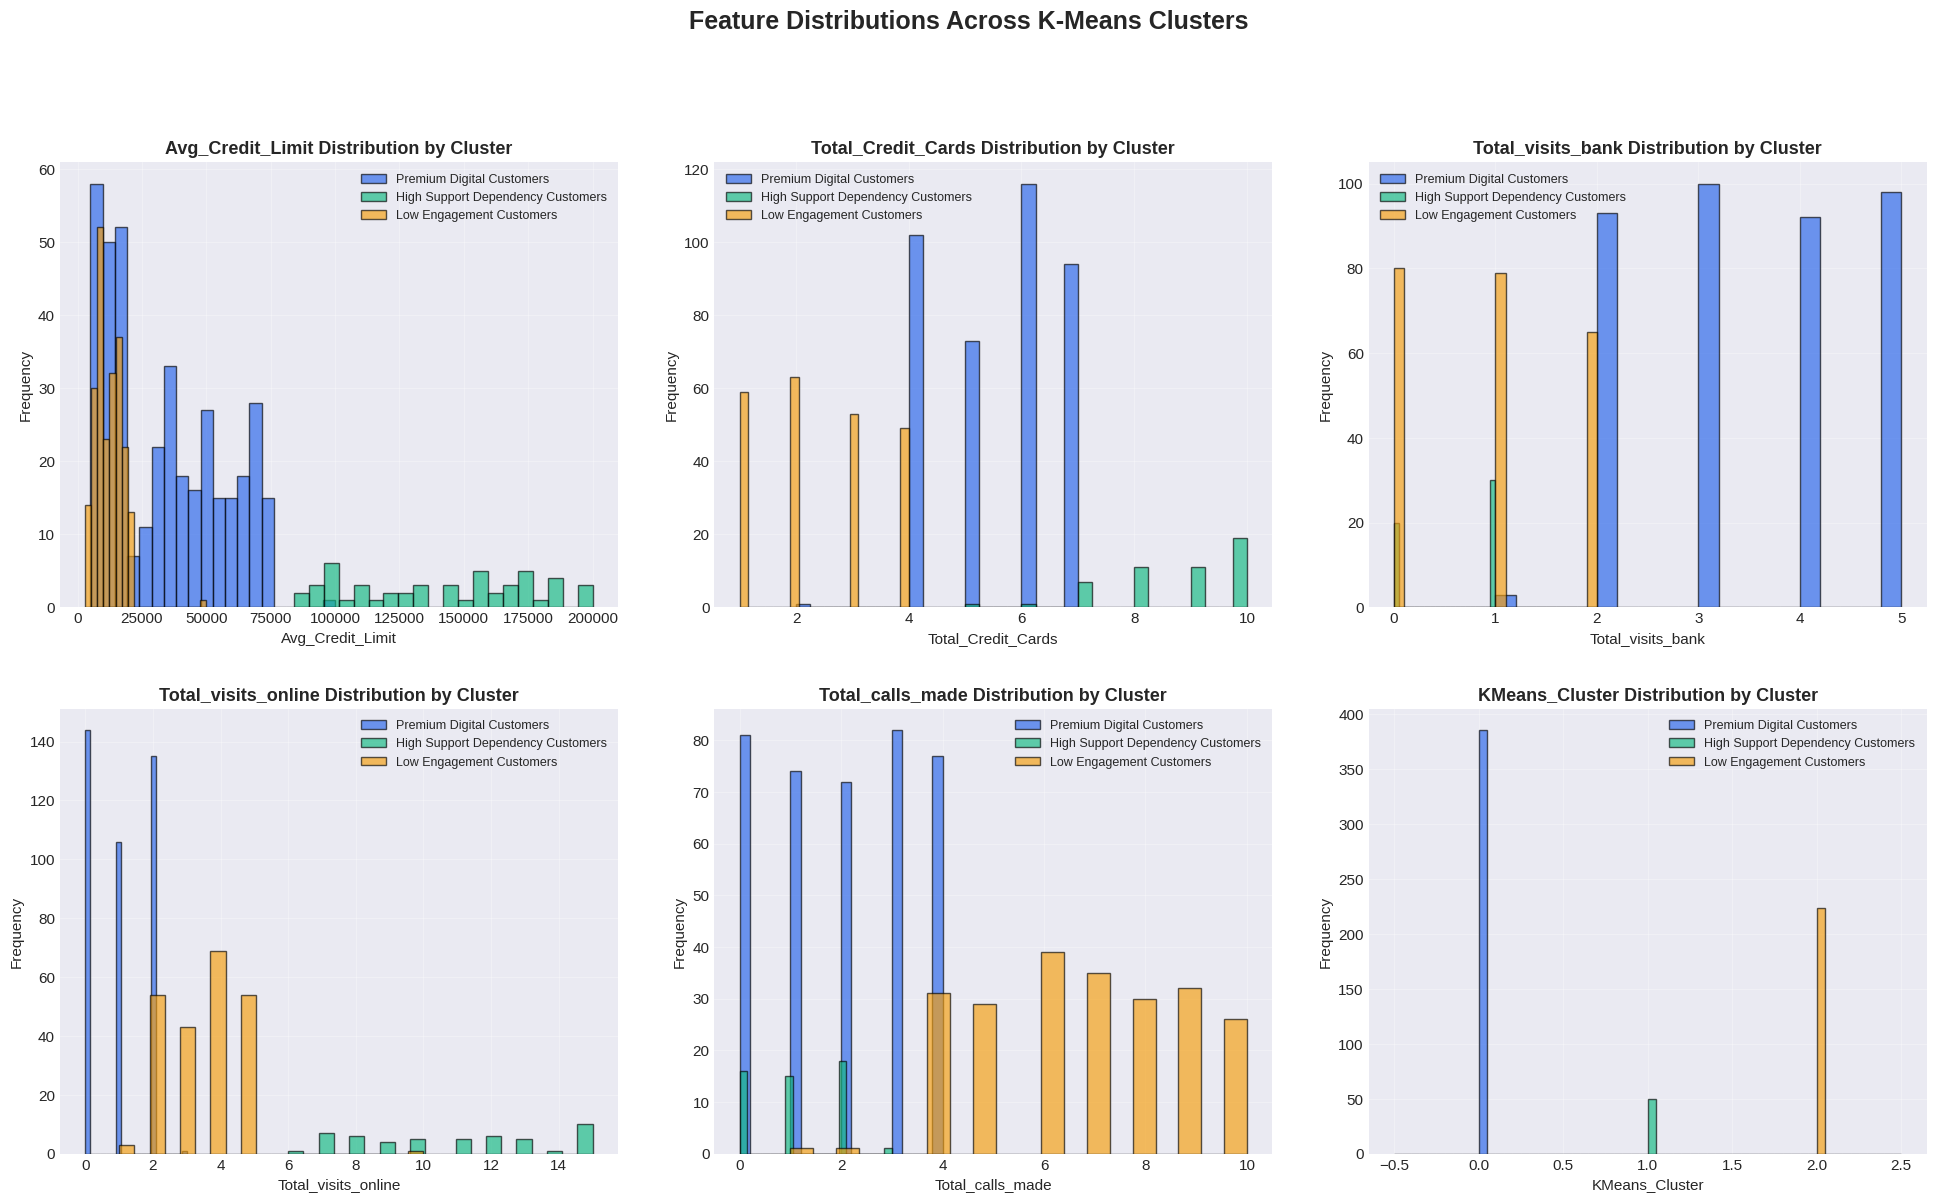

In [21]:
# ============================================================
# K-MEANS CLUSTER PROFILING AND SEGMENT ANALYSIS
# ============================================================

# This section performs:
# 1. K-Means cluster generation
# 2. Statistical cluster profiling
# 3. Feature distribution comparison
# 4. Segment interpretation support

# The objective is to understand behavioral differences
# across customer segments.


# ============================================================
# K-MEANS MODEL FITTING
# ============================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(
    df_scaled
)


# ============================================================
# Cluster Profile Summary Statistics
# ============================================================

cluster_profiles = df.groupby(
    'KMeans_Cluster'
).agg(
    ['mean', 'std', 'count']
).round(2)

print('='*60)
print('K-MEANS CLUSTER PROFILE SUMMARY')
print('='*60)

print(cluster_profiles)


# ============================================================
# Cluster Distribution Visualization
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 12),
    facecolor='white'
)

axes = axes.ravel()

features = df.columns


# ============================================================
# Professional Cluster Color Palette
# ============================================================

cluster_colors = {
    0: '#2563EB',
    1: '#10B981',
    2: '#F59E0B'
}

cluster_labels = {
    0: 'Premium Digital Customers',
    1: 'High Support Dependency Customers',
    2: 'Low Engagement Customers'
}


# ============================================================
# Feature Distribution Across Clusters
# ============================================================

for idx, feature in enumerate(features):

    if idx < len(axes):

        for cluster in range(3):

            cluster_data = df[
                df['KMeans_Cluster'] == cluster
            ][feature]

            axes[idx].hist(
                cluster_data,
                bins=20,
                alpha=0.65,
                color=cluster_colors[cluster],
                edgecolor='black',
                linewidth=1,
                label=cluster_labels[cluster]
            )

        axes[idx].set_title(
            f'{feature} Distribution by Cluster',
            fontsize=13,
            fontweight='bold'
        )

        axes[idx].set_xlabel(
            feature,
            fontsize=11
        )

        axes[idx].set_ylabel(
            'Frequency',
            fontsize=11
        )

        axes[idx].grid(
            alpha=0.3
        )

        axes[idx].legend(
            fontsize=9
        )


# ============================================================
# Hide Unused Subplots
# ============================================================

for idx in range(len(features), len(axes)):

    axes[idx].set_visible(False)


# ============================================================
# Overall Figure Formatting
# ============================================================

plt.suptitle(
    'Feature Distributions Across K-Means Clusters',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout(
    pad=3
)

plt.show()

### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [22]:
for k in range(2,10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, labels)
    print(f'k={k}, Silhouette Score={score}')

k=2, Silhouette Score=0.5703183487340514
k=3, Silhouette Score=0.5157182558881063
k=4, Silhouette Score=0.3556670619372605
k=5, Silhouette Score=0.332312434784495
k=6, Silhouette Score=0.2572826107002575
k=7, Silhouette Score=0.2397404411036028
k=8, Silhouette Score=0.2290267171721957
k=9, Silhouette Score=0.21634358879383397


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [23]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['KMeans_Cluster'] = kmeans.fit_predict(df_scaled)
df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,KMeans_Cluster,Hierarchical_Cluster
0,100000,2,1,1,0,0,3
1,50000,3,0,10,9,2,1
2,50000,7,1,3,4,0,3
3,30000,5,1,1,4,0,3
4,100000,6,0,12,3,1,2


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [24]:
df.groupby('KMeans_Cluster').mean()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Hierarchical_Cluster
KMeans_Cluster,,,,,,
0,33782.383420,5.515544,3.489637,0.981865,2.000000,2.994819
1,141040.000000,8.740000,0.600000,10.900000,1.080000,2.000000
2,12174.107143,2.410714,0.933036,3.553571,6.870536,1.000000


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


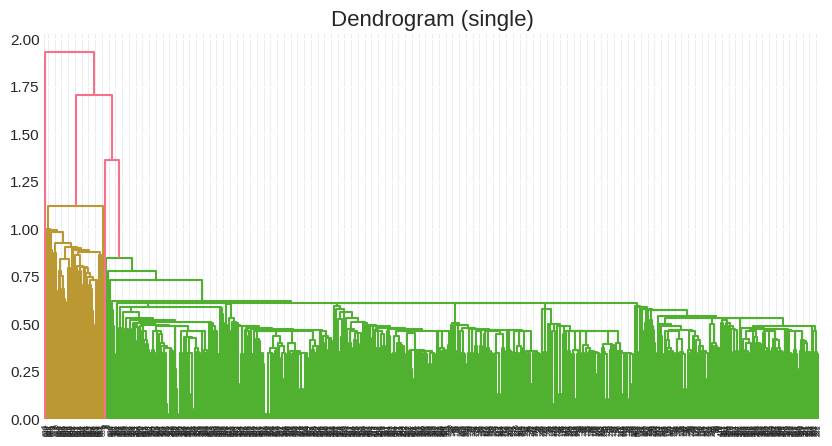

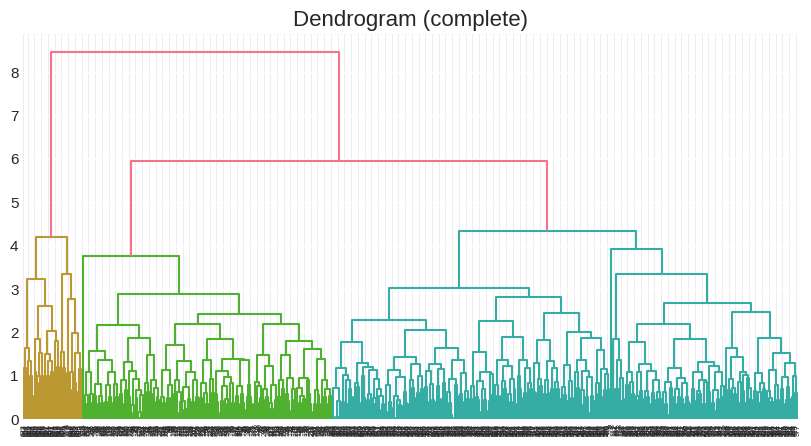

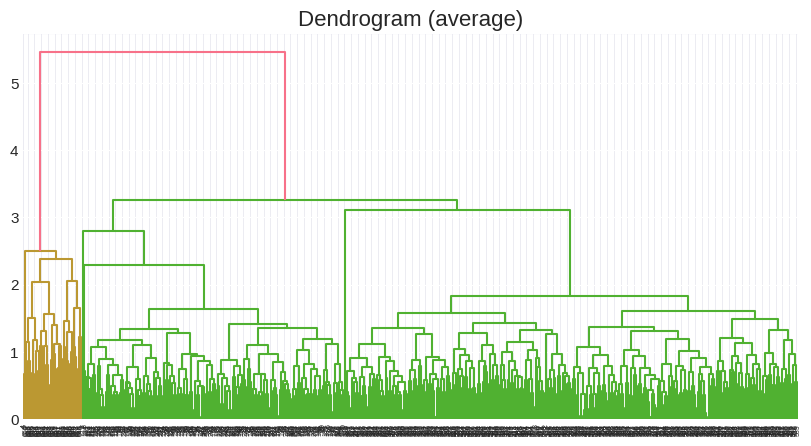

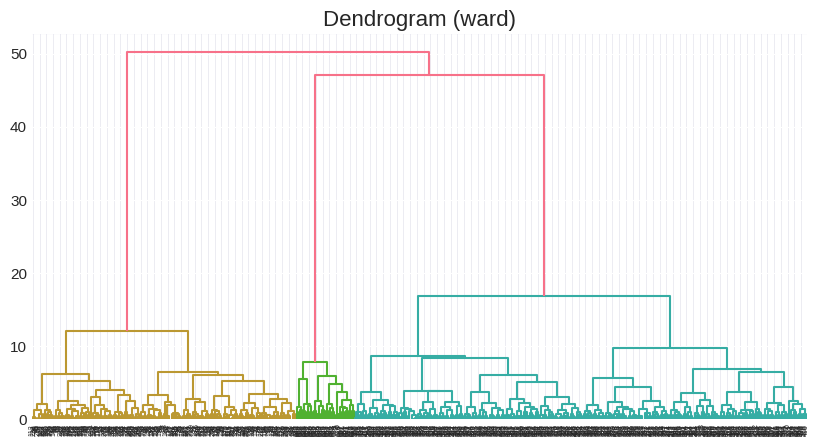

In [25]:
linkage_methods = ['single', 'complete', 'average', 'ward']

for method in linkage_methods:
    Z = linkage(df_scaled, method=method)
    plt.figure(figsize=(10,5))
    dendrogram(Z)
    plt.title(f'Dendrogram ({method})')
    plt.show()

### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [26]:
from scipy.cluster.hierarchy import cophenet

for method in linkage_methods:
    Z = linkage(df_scaled, method=method)
    c, _ = cophenet(Z, pdist(df_scaled))
    print(f'{method} linkage cophenetic correlation: {c}')

single linkage cophenetic correlation: 0.7391220243806552
complete linkage cophenetic correlation: 0.8599730607972423
average linkage cophenetic correlation: 0.8977080867389372
ward linkage cophenetic correlation: 0.7415156284827493


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [27]:
Z = linkage(df_scaled, method='ward')
df['Hierarchical_Cluster'] = fcluster(Z, 3, criterion='maxclust')
df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,KMeans_Cluster,Hierarchical_Cluster
0,100000,2,1,1,0,0,3
1,50000,3,0,10,9,2,1
2,50000,7,1,3,4,0,3
3,30000,5,1,1,4,0,3
4,100000,6,0,12,3,1,2


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [28]:
df.groupby('Hierarchical_Cluster').mean()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,KMeans_Cluster
Hierarchical_Cluster,,,,,,
1,12151.111111,2.422222,0.937778,3.546667,6.857778,1.991111
2,141040.000000,8.740000,0.600000,10.900000,1.080000,1.000000
3,33851.948052,5.516883,3.493506,0.979221,1.994805,0.000000


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [29]:
pd.crosstab(df['KMeans_Cluster'], df['Hierarchical_Cluster'])

Hierarchical_Cluster,1,2,3
KMeans_Cluster,,,
0,1,0,385
1,0,50,0
2,224,0,0


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


In [30]:
df.to_csv('clustered_output.csv', index=False)

### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.


## 7. Business Insights & Recommendations

## Key Insights

- High spenders with low support interaction
- Frequent callers indicating service issues
- Digitally active customers


## Recommendations

- Target high spenders with premium cards
- Improve service for high-call customers
- Promote digital channels for low online users


### 🔍 Insights:
- Clearly describe what this output shows.
- Mention trends, patterns, or anomalies.
- Explain how this impacts business decisions.
